# Quantum BLOOM
**IQ Hackathon | October 24, 2026**

### Breast cancer classification with quantum kernels

We compare a quantum-kernel SVM with two classical RBF SVMs on the Wisconsin Diagnostic Breast Cancer dataset.

**Question:** How do PCA and quantum encoding affect classification performance?

| Part | Work |
|---|---|
| 1 | Data preparation, PCA and classical baselines |
| 2 | Four-qubit ZZ feature map |
| 3 | Kernel matrices and measurement |
| 4 | Quantum SVM and model comparison |

**Shared setup**

- `random_state=42`; 80/20 stratified split
- Malignant = 1; benign = 0
- The same stratified subset of 120 training observations for all three models
- PCA with four components for the reduced models
- Four-qubit ZZ feature map and `FidelityStatevectorKernel`
- The same held-out test observations for every model

The full-feature RBF model gives us a reference for the effect of PCA. Comparing the two PCA models isolates the kernel choice.


In [ ]:
import importlib.util, subprocess, sys
needed = {'IPython':'ipython','numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib',
          'sklearn':'scikit-learn','qiskit':'qiskit>=2,<3',
          'qiskit_machine_learning':'qiskit-machine-learning>=0.9,<0.10'}
missing = [package for module,package in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])

import json, time, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn, qiskit, qiskit_machine_learning
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, recall_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
SEED = 42
N_COMPONENTS = 4
TRAIN_SUBSET_SIZE = 120   # Set to None to use all 455 training observations.
REPS = 2
C = 1.0                  # Fixed common first-run regularization; no test-based tuning.
OUT = Path('breast_cancer_qml_results'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'font.size':11})
BLUE, ORANGE = '#2a78d6', '#eb6834'
versions = {'python':platform.python_version(),'numpy':np.__version__,
 'scikit-learn':sklearn.__version__,'qiskit':qiskit.__version__,
 'qiskit-machine-learning':qiskit_machine_learning.__version__}
display(pd.Series(versions,name='version'))

,version
python,3.13.16
numpy,2.1.3
scikit-learn,1.6.1
qiskit,2.6.1
qiskit-machine-learning,0.9.1


---
# Part 1 · Data and classical baselines
## 1.1 Dataset and split
Each observation has 30 measurements and a benign or malignant label. We reserve 20% for testing, then take a stratified subset from the training partition. All three models use the same sample IDs.


In [ ]:
dataset = load_breast_cancer()
X = dataset.data.astype(float)
y = (dataset.target == list(dataset.target_names).index('malignant')).astype(int)
all_ids = np.arange(len(y))
train_pool_ids, test_ids = train_test_split(all_ids,test_size=0.2,
                                          stratify=y,random_state=SEED)
if TRAIN_SUBSET_SIZE is None or TRAIN_SUBSET_SIZE >= len(train_pool_ids):
    train_ids = train_pool_ids.copy()
else:
    train_ids,_ = train_test_split(train_pool_ids,train_size=TRAIN_SUBSET_SIZE,
                                  stratify=y[train_pool_ids],random_state=SEED)
X_train_raw,X_test_raw = X[train_ids],X[test_ids]
y_train,y_test = y[train_ids],y[test_ids]
assert not set(train_ids) & set(test_ids)
assert np.isfinite(X).all()
print(f'Total: {len(y)} | train pool: {len(train_pool_ids)} | used train: {len(train_ids)} | test: {len(test_ids)}')
display(pd.DataFrame({'train':pd.Series(y_train).value_counts(),
                      'test':pd.Series(y_test).value_counts()})
        .rename(index={0:'benign',1:'malignant'}))
np.savez(OUT/'observation_ids.npz',train_pool=train_pool_ids,train=train_ids,test=test_ids)

Total: 569 | train pool: 455 | used train: 120 | test: 114


,train,test
benign,75,72
malignant,45,42


## 1.2 PCA and scaling
Standardization and PCA are fitted on the selected training observations only. We scale the four PCA coordinates to [0, π] and give the same inputs to the reduced RBF model and the quantum model. Test coordinates outside the training range are clipped.

The reference RBF model uses all 30 standardized features. Both RBF models start with `C=1` and `gamma="scale"`; these are baseline settings rather than tuned results.


Quantum / matched RBF input shapes: (120, 4) (114, 4)
PCA explained variance: [0.431 0.208 0.097 0.074]
Total retained variance: 0.809


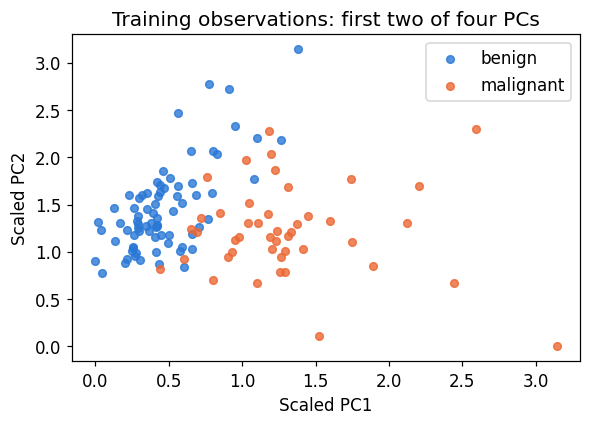

Both classical baselines trained.


In [ ]:
t = time.perf_counter()
scaler = StandardScaler().fit(X_train_raw)
X_train_full = scaler.transform(X_train_raw)
X_test_full = scaler.transform(X_test_raw)
standardization_seconds = time.perf_counter()-t

t = time.perf_counter()
pca = PCA(n_components=N_COMPONENTS,svd_solver='full').fit(X_train_full)
train_pc,test_pc = pca.transform(X_train_full),pca.transform(X_test_full)
angle_scaler = MinMaxScaler(feature_range=(0,np.pi),clip=True).fit(train_pc)
X_train = angle_scaler.transform(train_pc)
X_test = angle_scaler.transform(test_pc)
reduction_seconds = time.perf_counter()-t
print('Quantum / matched RBF input shapes:',X_train.shape,X_test.shape)
print('PCA explained variance:',pca.explained_variance_ratio_.round(3))
print('Total retained variance:',round(pca.explained_variance_ratio_.sum(),3))
fig,ax = plt.subplots(figsize=(5.5,4))
for label,name,color in [(0,'benign',BLUE),(1,'malignant',ORANGE)]:
    ax.scatter(*X_train[y_train==label,:2].T,label=name,color=color,s=25,alpha=.8)
ax.set(xlabel='Scaled PC1',ylabel='Scaled PC2',title='Training observations: first two of four PCs')
ax.legend(); plt.tight_layout(); plt.show()

models = {}; timings = {}
for name,a,b in [('RBF SVM · 30 features',X_train_full,X_test_full),
                  ('RBF SVM · PCA 4',X_train,X_test)]:
    model = SVC(kernel='rbf',C=C,gamma='scale')
    t = time.perf_counter(); model.fit(a,y_train)
    fit_seconds = time.perf_counter()-t
    models[name] = {'model':model,'test_input':b}
    timings[name] = {'fit_seconds':fit_seconds,'kernel_seconds':0.0,
                    'preprocessing_seconds':standardization_seconds +
                        (reduction_seconds if a.shape[1]==N_COMPONENTS else 0)}
print('Both classical baselines trained.')

---
# Part 2 · Quantum feature map
The circuit encodes each observation as a state:

$$|\phi(x)\rangle = U(x)|0000\rangle.$$

The kernel measures the overlap between two encoded observations:

$$k(x,x') = |\langle\phi(x')|\phi(x)\rangle|^2.$$

## 2.1 Four features, four qubits
We use the standard Qiskit ZZ map with two repetitions and linear entanglement. Its pairwise phase is (π−xᵢ)(π−xⱼ), following the lecture example. The optional bandwidth experiment uses a different phase definition, noted below.


In [ ]:
feature_map = zz_feature_map(feature_dimension=N_COMPONENTS,reps=REPS,entanglement='linear')
print(feature_map.draw(output='text',fold=100))
print('Qubits:',feature_map.num_qubits,'| depth:',feature_map.depth())
print('Gates:',dict(feature_map.count_ops()))

def kernel_from_states(circuit,x1,x2):
    s1 = Statevector(circuit.assign_parameters(np.asarray(x1)))
    s2 = Statevector(circuit.assign_parameters(np.asarray(x2)))
    return float(abs(s2.inner(s1))**2)

x_a,x_b = X_train[0],X_train[1]
k_exact = kernel_from_states(feature_map,x_a,x_b)
print(f'Example kernel similarity: {k_exact:.6f}')
assert np.isclose(kernel_from_states(feature_map,x_a,x_a),1.0)

   ┌───┐┌───────────┐                                          ┌───┐»
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘»
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«            ┌───────────┐                                                         »
«0: ─────────┤ P(2*x[0]) ├──────────────────────────────────────────────────────■──»
«            └───────────┘               ┌───┐         ┌───────────┐          ┌─┴─┐»
«1: ──────────────────────────────────■──┤ H ├─────────┤ P(2*x[1]) ├──────────┤ X ├»
«   ┌─────────────────────────

---
# Part 3 · Quantum kernel
## 3.1 Measurement check
Applying U(x), then U†(x′), gives an all-zero measurement probability equal to the kernel value. We compare a 2,048-shot estimate with the exact statevector overlap for one pair.

`StatevectorSampler` introduces sampling variation, but does not simulate device noise. The main classifier uses exact kernels.


In [ ]:
from qiskit.primitives import StatevectorSampler
qc_kernel = feature_map.assign_parameters(x_a).compose(
    feature_map.assign_parameters(x_b).inverse())
qc_kernel.measure_all()
shots = 2048
sampler = StatevectorSampler(seed=SEED)
counts = sampler.run([qc_kernel],shots=shots).result()[0].data.meas.get_counts()
k_shots = counts.get('0'*N_COMPONENTS,0)/shots
print(f'Exact kernel: {k_exact:.5f} | {shots}-shot estimate: {k_shots:.5f}')
print('Sampling standard error (using exact probability):',np.sqrt(k_exact*(1-k_exact)/shots))

Exact kernel: 0.17509 | 2048-shot estimate: 0.17822
Sampling standard error (using exact probability): 0.008397877133896092


## 3.2 Kernel matrices
`FidelityStatevectorKernel` computes the exact simulated similarities. The training matrix is N×N; the test matrix is M×N.

We save both matrices so they can be reused with different SVM regularization values. Changes to preprocessing or the feature map require new matrices. Hardware overlap measurements would need roughly quadratic numbers of pairs; statevector simulation can reuse the encoded states.


Exact kernel construction: 2.558 s
Equivalent pair counts for compute–uncompute:
Training: 7140 | test: 13680


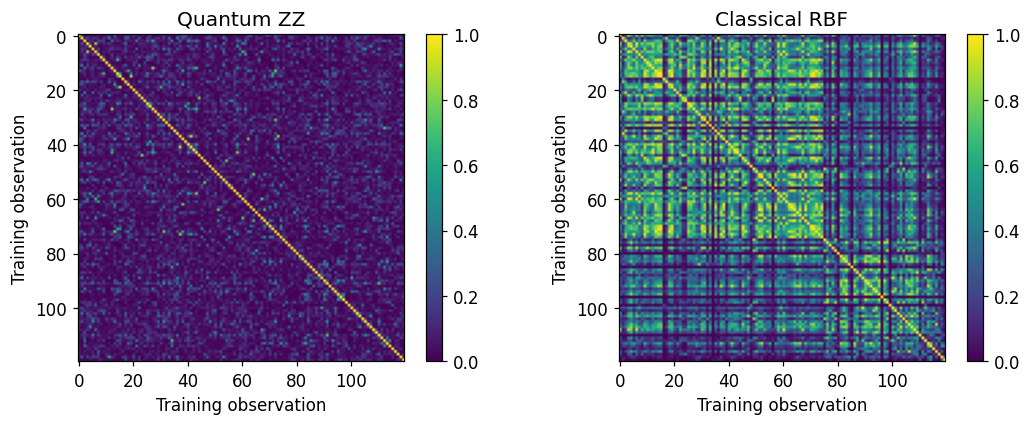

In [ ]:
from sklearn.metrics.pairwise import rbf_kernel
qkernel = FidelityStatevectorKernel(feature_map=feature_map)
t = time.perf_counter()
K_train_q = qkernel.evaluate(X_train)
K_test_q = qkernel.evaluate(X_test,X_train)
kernel_seconds = time.perf_counter()-t
assert K_train_q.shape == (len(y_train),len(y_train))
assert K_test_q.shape == (len(y_test),len(y_train))
assert np.allclose(K_train_q,K_train_q.T,atol=1e-8)
assert np.allclose(np.diag(K_train_q),1.0,atol=1e-8)
assert np.isclose(K_train_q[0,1],k_exact,atol=1e-8)
np.savez_compressed(OUT/'baseline_kernels.npz',train=K_train_q,test=K_test_q,
                    train_ids=train_ids,test_ids=test_ids)
print(f'Exact kernel construction: {kernel_seconds:.3f} s')
print('Equivalent pair counts for compute–uncompute:')
print('Training:',len(y_train)*(len(y_train)-1)//2,'| test:',len(y_test)*len(y_train))
order = np.argsort(y_train)
rbf_gamma = models['RBF SVM · PCA 4']['model']._gamma
K_rbf = rbf_kernel(X_train,gamma=rbf_gamma)
fig,axes = plt.subplots(1,2,figsize=(10,4))
for ax,K,name in [(axes[0],K_train_q,'Quantum ZZ'),(axes[1],K_rbf,'Classical RBF')]:
    im=ax.imshow(K[np.ix_(order,order)],vmin=0,vmax=1,cmap='viridis')
    ax.set(title=name,xlabel='Training observation',ylabel='Training observation')
    fig.colorbar(im,ax=ax,fraction=.046)
plt.tight_layout(); plt.savefig(OUT/'kernel_matrices.png',dpi=150); plt.show()

---
# Part 4 · Quantum SVM and comparison
## 4.1 Train the classifier
We pass the quantum kernel matrices to `SVC(kernel="precomputed")`. The similarities come from the quantum feature map; SVM training remains classical. This follows the precomputed-kernel approach in the lecture.


In [ ]:
svm_q = SVC(kernel='precomputed',C=C)
t = time.perf_counter(); svm_q.fit(K_train_q,y_train)
quantum_fit_seconds = time.perf_counter()-t
quantum_name = 'Quantum ZZ SVM · PCA 4'
models[quantum_name] = {'model':svm_q,'test_input':K_test_q}
timings[quantum_name] = {'fit_seconds':quantum_fit_seconds,'kernel_seconds':kernel_seconds,
                        'preprocessing_seconds':standardization_seconds+reduction_seconds}

## 4.2 Three-model results
We evaluate the fixed baseline settings on the held-out test set. Metrics are ROC-AUC, malignant recall, balanced accuracy and accuracy. ROC-AUC uses `decision_function`; recall uses the default SVM decision threshold.

Timing includes preprocessing, fitting and test prediction. For the quantum model, kernel construction is recorded separately. For the RBF models, kernel computation happens inside fitting and prediction. Installation and plotting are excluded.


,model,train_n,test_n,accuracy,balanced_accuracy,malignant_recall,roc_auc,fit_seconds,kernel_seconds,preprocessing_seconds,prediction_seconds,total_seconds
0,RBF SVM · 30 features,120,114,0.9649,0.9573,0.9286,0.994,0.0063,0.0000,0.0061,0.0191,0.0315
1,RBF SVM · PCA 4,120,114,0.9298,0.9097,0.8333,0.994,0.0060,0.0000,0.0445,0.0134,0.0639
2,Quantum ZZ SVM · PCA 4,120,114,0.6404,0.5665,0.2857,0.706,0.0068,2.5584,0.0445,0.0055,2.6153


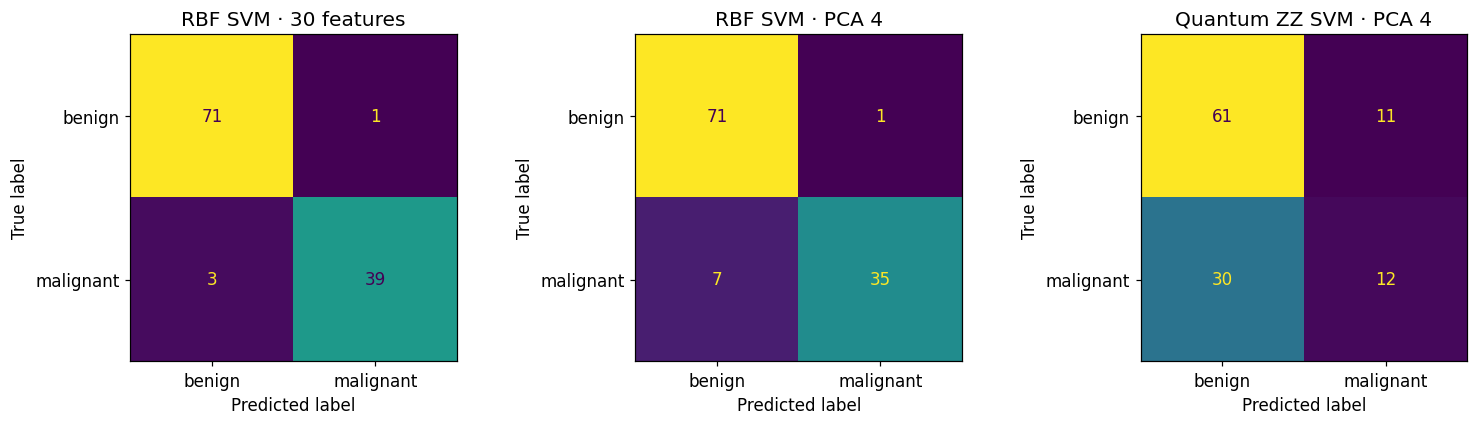

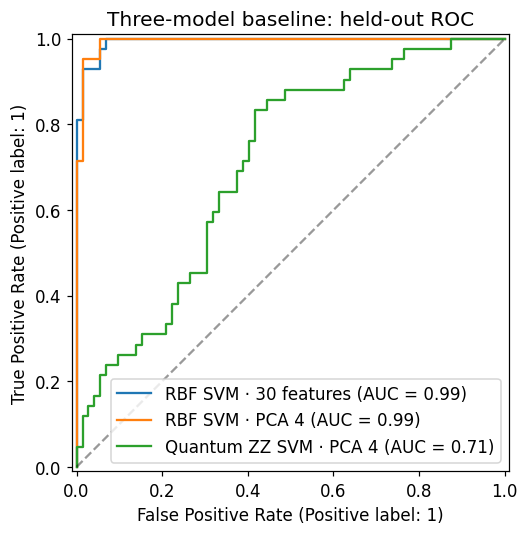

In [ ]:
result_rows = []
for name,item in models.items():
    t = time.perf_counter()
    pred = item['model'].predict(item['test_input'])
    score = item['model'].decision_function(item['test_input'])
    prediction_seconds = time.perf_counter()-t
    item.update(predictions=pred,scores=score)
    timing = dict(timings[name],prediction_seconds=prediction_seconds)
    result_rows.append(dict(model=name,train_n=len(y_train),test_n=len(y_test),
        accuracy=accuracy_score(y_test,pred),balanced_accuracy=balanced_accuracy_score(y_test,pred),
        malignant_recall=recall_score(y_test,pred,zero_division=0),roc_auc=roc_auc_score(y_test,score),
        **timing,total_seconds=sum(timing.values())))
results = pd.DataFrame(result_rows)
display(results.round(4))
results.to_csv(OUT/'three_model_baseline.csv',index=False)

fig,axes = plt.subplots(1,3,figsize=(14,4))
for ax,(name,item) in zip(axes,models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,item['predictions'],
        display_labels=['benign','malignant'],ax=ax,colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrices.png',dpi=150); plt.show()
fig,ax = plt.subplots(figsize=(7,5))
for name,item in models.items():
    RocCurveDisplay.from_predictions(y_test,item['scores'],name=name,ax=ax)
ax.plot([0,1],[0,1],'k--',alpha=.4); ax.set_title('Three-model baseline: held-out ROC')
plt.tight_layout(); plt.savefig(OUT/'roc_curves.png',dpi=150); plt.show()

## 4.3 Further experiments
Set `RUN_EXTENSIONS=True` to compare two and four PCA components, RBF and quantum encodings, and two bandwidths. This section is off by default.

The experiments use three-fold validation within the selected training subset. Preprocessing is refitted within each fold. The RBF model also has an inner parameter search.

The extension ZZ map uses xᵢxⱼ pairwise phases from lecture Part 5, rather than the baseline's (π−xᵢ)(π−xⱼ). The scale λ controls the input angles. Independent RY rotations provide a classically tractable encoding comparison.

Use validation scores for these choices. Since the baseline test scores are already visible, further tuning should not rely on them; confirmatory evaluation would need fresh data or an independently planned evaluation.


In [ ]:
RUN_EXTENSIONS = False

def product_phase(values):
    return values[0] if len(values)==1 else values[0]*values[1]

def extension_map(k,kind):
    if kind=='zz_product_phase':
        return zz_feature_map(k,reps=REPS,entanglement='linear',data_map_func=product_phase)
    circuit = QuantumCircuit(k); x = ParameterVector('x',k)
    for j in range(k): circuit.ry(x[j],j)
    return circuit

if RUN_EXTENSIONS:
    fold_indices = list(StratifiedKFold(3,shuffle=True,random_state=SEED).split(X_train_raw,y_train))
    extension_rows = []
    for k in [2,4]:
        for fold,(tr,va) in enumerate(fold_indices):
            prep = Pipeline([('scale',StandardScaler()),('pca',PCA(k,svd_solver='full')),
                             ('angles',MinMaxScaler(feature_range=(0,np.pi),clip=True))])
            a = prep.fit_transform(X_train_raw[tr],y_train[tr]); b = prep.transform(X_train_raw[va])
            # Classical search stays inside this training fold.
            inner = StratifiedKFold(3,shuffle=True,random_state=SEED)
            # Inner preprocessing must also be refit: search on RAW outer-training features.
            pipe = Pipeline([('scale',StandardScaler()),('pca',PCA(k,svd_solver='full')),
                ('angles',MinMaxScaler(feature_range=(0,np.pi),clip=True)),('svm',SVC(kernel='rbf'))])
            search = GridSearchCV(pipe,{'svm__C':[.1,1,10],'svm__gamma':['scale',.1,1]},
                                  scoring='roc_auc',cv=inner)
            t = time.perf_counter(); search.fit(X_train_raw[tr],y_train[tr])
            extension_rows.append(dict(k=k,fold=fold,encoding='rbf_tuned',bandwidth=0,C=search.best_params_['svm__C'],
                auc=roc_auc_score(y_train[va],search.decision_function(X_train_raw[va])),seconds=time.perf_counter()-t))
            for kind in ['product_ry','zz_product_phase']:
                for lam in [.3,1.0]:
                    kernel = FidelityStatevectorKernel(feature_map=extension_map(k,kind))
                    t = time.perf_counter(); kt=kernel.evaluate(lam*a); kv=kernel.evaluate(lam*b,lam*a)
                    construction = time.perf_counter()-t
                    for c in [.1,1,10]:
                        t = time.perf_counter(); m=SVC(kernel='precomputed',C=c).fit(kt,y_train[tr])
                        scores=m.decision_function(kv)
                        extension_rows.append(dict(k=k,fold=fold,encoding=kind,bandwidth=lam,C=c,
                            auc=roc_auc_score(y_train[va],scores),seconds=construction+time.perf_counter()-t))
    extension_results = pd.DataFrame(extension_rows)
    extension_results.to_csv(OUT/'extension_validation_folds.csv',index=False)
    extension_summary = extension_results.groupby(['k','encoding','bandwidth','C'],as_index=False).agg(
        mean_auc=('auc','mean'),sd_auc=('auc','std'),mean_seconds=('seconds','mean'))
    display(extension_summary.sort_values('mean_auc',ascending=False).round(4))
    print('Exploratory CV scores; selecting the best quantum configuration can produce optimistic validation estimates.')
else:
    print('Extensions disabled. Set RUN_EXTENSIONS=True to explore using training data only.')

Extensions disabled. Set RUN_EXTENSIONS=True to explore using training data only.


## 4.4 Discussion

- How much changes when the RBF model goes from 30 features to four PCs?
- On the same PCA inputs, how does the ZZ kernel compare with RBF?
- Which errors are malignant false negatives and which are benign false positives?
- How much time goes into kernel construction compared with SVM fitting?

These results describe one small training subset and one test split. The first run uses fixed parameters. Simulation timings do not establish a hardware speedup, and classification scores do not establish clinical usefulness. VQC and hardware runs are outside this first experiment.

### References

- QML_1_Lecture(1).ipynb — feature maps, kernels and compute–uncompute
- [scikit-learn: Wisconsin Breast Cancer dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
- [Qiskit Machine Learning: kernels](https://qiskit-community.github.io/qiskit-machine-learning/apidocs/qiskit_machine_learning.kernels.html)


In [ ]:
config = {'seed':SEED,'test_size':0.2,'stratified':True,'positive_class':'malignant',
 'training_subset_size':len(train_ids),'pca_components':N_COMPONENTS,'C':C,'rbf_gamma':'scale',
 'feature_map':'standard zz_feature_map','reps':REPS,'entanglement':'linear',
 'angle_range':[0,float(np.pi)],'test_angle_clipping':True,'versions':versions}
(OUT/'experiment_configuration.json').write_text(json.dumps(config,indent=2))
np.savez_compressed(OUT/'prepared_observations.npz',X_train=X_train,X_test=X_test,
                    y_train=y_train,y_test=y_test,train_ids=train_ids,test_ids=test_ids)
print('Saved shared observations, kernel matrices, scores, configuration and plots to:',OUT.resolve())

Saved shared observations, kernel matrices, scores, configuration and plots to: /content/breast_cancer_qml_results
